In [5]:
from google.colab import drive
import pandas as pd
import pickle
import shap
#drive.mount('/content/drive')
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [2]:
data = pd.read_csv(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ BGGN .csv")
selected_columns = data[['uniqueID', 'PointLatit', 'PointLongi', 'Predicted']]

In [3]:
species_list = ["BGGN"] # Shrubland

for species in species_list:

  with open(f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/{species}_8Predictors.pkl', 'rb') as f:
      shap_values = pickle.load(f)
shap_df = pd.DataFrame(shap_values)
shap_df[1:10]

,0,1,2,3,4,5,6,7
1,-0.015793,0.0,0.018361,-0.077510,0.0,-0.072463,-0.010165,0.454597
2,-0.015793,0.0,0.018361,-0.077510,0.0,-0.072463,-0.010165,0.454597
3,-0.042936,0.0,0.024496,-0.100142,0.0,-0.137288,-0.026248,0.356199
4,-0.042936,0.0,0.024496,-0.100142,0.0,-0.137288,-0.026248,0.356199
5,-0.000521,0.0,0.025192,0.003640,0.0,0.024785,-0.037626,0.014316
6,-0.042936,0.0,0.024496,-0.100142,0.0,-0.137288,-0.026248,0.356199
7,-0.042936,0.0,0.024496,-0.100142,0.0,-0.137288,-0.026248,0.356199
8,-0.042936,0.0,0.024496,-0.100142,0.0,-0.137288,-0.026248,0.356199
9,0.003365,0.0,0.017764,-0.004633,0.0,-0.008537,-0.070760,0.011525


In [ ]:
import matplotlib.pyplot as plt
import shap
shap.initjs()
predictor_cols = [
      'CumDHI', 'DEM', '%Forest', '%Grassland', 'Precipitation', '%Shrubland', 'Temperature', 'VarDHI' ]
# Plot SHAP dependence plots for all predictors
for col in predictor_cols:
    shap_values.dependence_plot(col, shap_values, X)
    plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'dependence_plot'

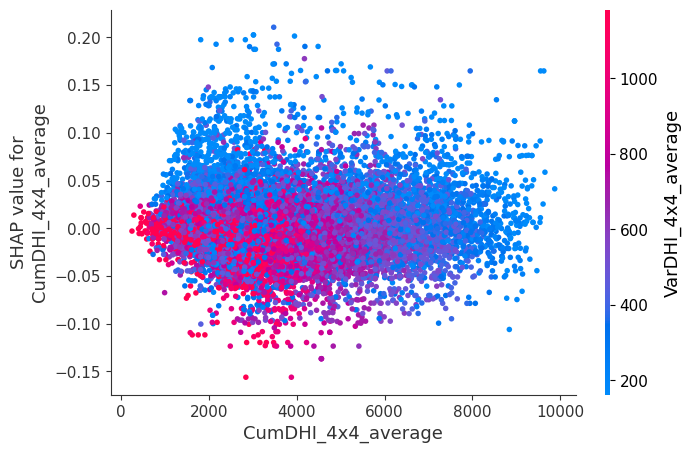

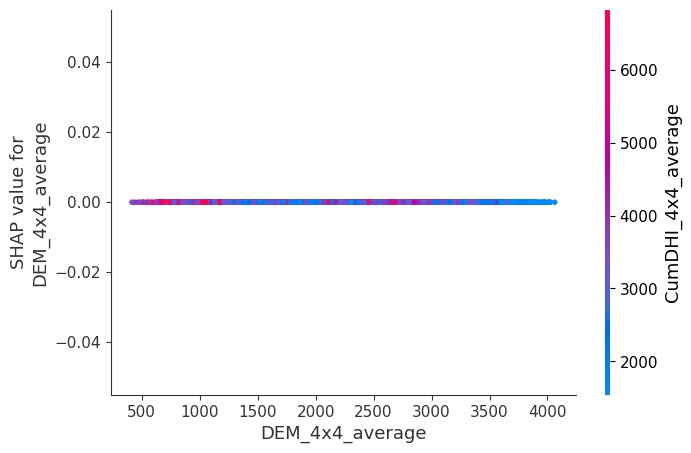

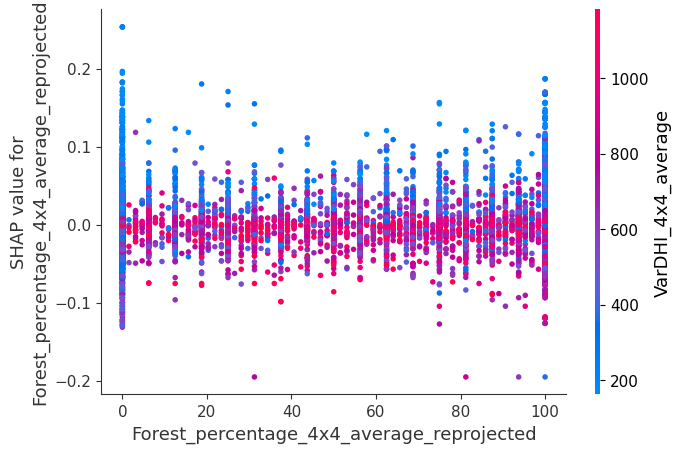

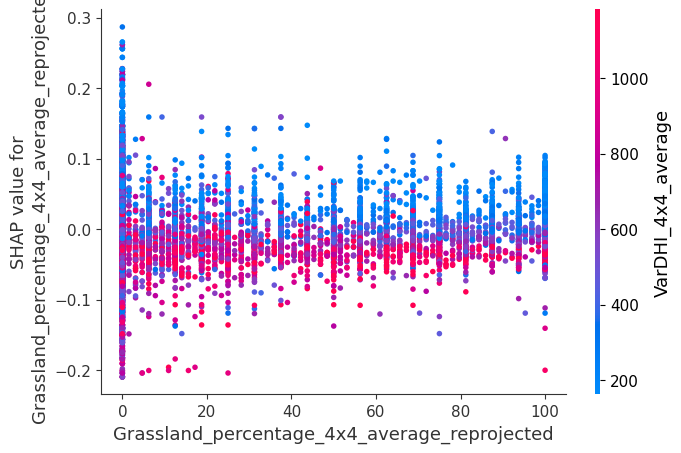

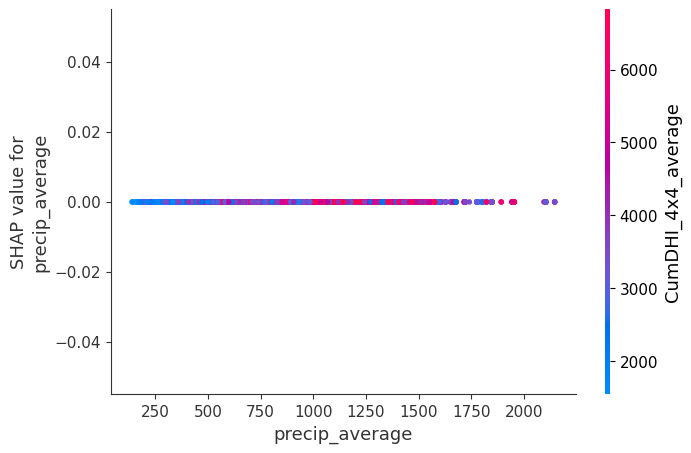

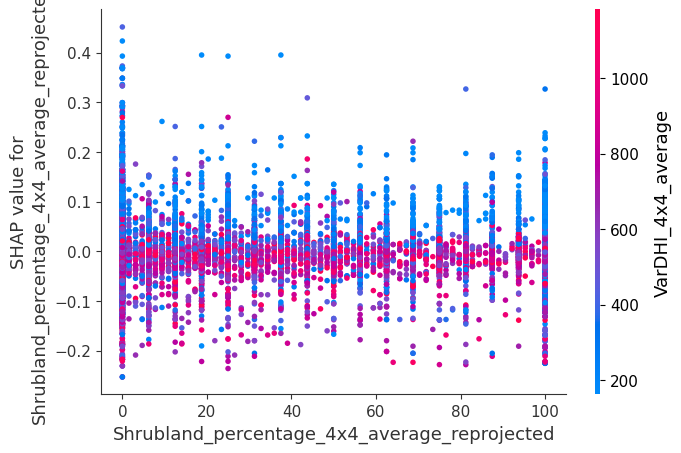

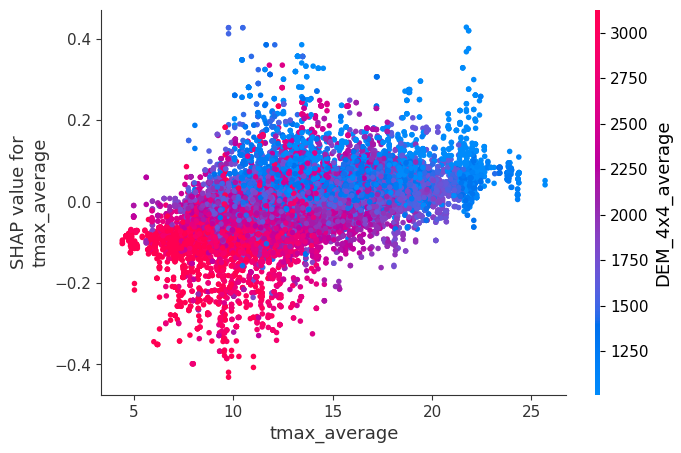

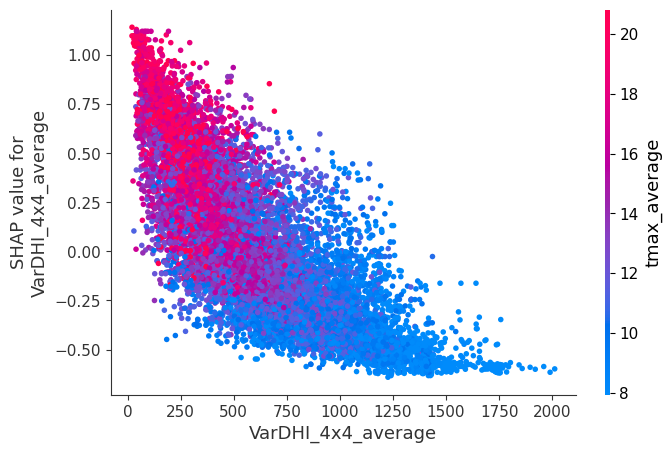

In [9]:
import matplotlib.pyplot as plt

# Load the data
data_path = "/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ BGGN .csv"
data = pd.read_csv(data_path)

# Load SHAP values
species_list = ["BGGN"]

for species in species_list:
    shap_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/{species}_8Predictors.pkl'
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

# Define the predictor columns used in your model
predictor_cols = ['CumDHI_4x4_average', 'DEM_4x4_average', 'Forest_percentage_4x4_average_reprojected', 'Grassland_percentage_4x4_average_reprojected', 'precip_average', 'Shrubland_percentage_4x4_average_reprojected', 'tmax_average', 'VarDHI_4x4_average']  # Update with your actual columns
X = data[predictor_cols]

# Plot SHAP dependence plots for each predictor
for col in predictor_cols:
    shap.dependence_plot(col, shap_values, X)
    plt.show()

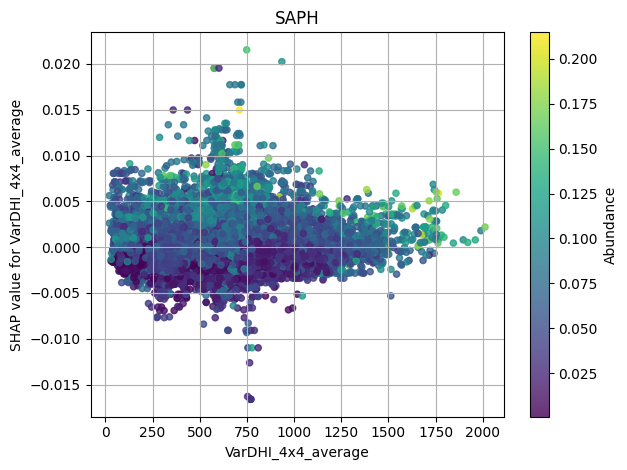

In [ ]:
import pandas as pd
import shap
import pickle
import matplotlib.pyplot as plt


for species in species_list:
    # Load the data
    data_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ {species} .csv'
    data = pd.read_csv(data_path)
    shap_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/{species}_8Predictors.pkl'
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

# Define predictors and feature matrix
# predictor_cols = [
#     'CumDHI_4x4_average', 'DEM_4x4_average',
#     'Forest_percentage_4x4_average_reprojected', 'Grassland_percentage_4x4_average_reprojected',
#     'precip_average', 'Shrubland_percentage_4x4_average_reprojected',
#     'tmax_average', 'VarDHI_4x4_average'
# ]

predictor_cols = ['VarDHI_4x4_average']
X = data[predictor_cols]

# Use shap_values as a numpy array
shap_values = shap_values.values if hasattr(shap_values, "values") else shap_values

# Loop through each feature and plot with Predicted values as color
for i, col in enumerate(predictor_cols):
    plt.figure()
    plt.scatter(
        X[col],               # x-axis: feature value
        shap_values[:, i],    # y-axis: SHAP value for this feature
        c=data['Predicted'],  # color: predicted values
        cmap='viridis',
        s=20,
        alpha=0.8
    )
    plt.xlabel(col)
    plt.ylabel(f'SHAP value for {col}')
    plt.colorbar(label='Abundance')
    plt.title(f'{species}')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


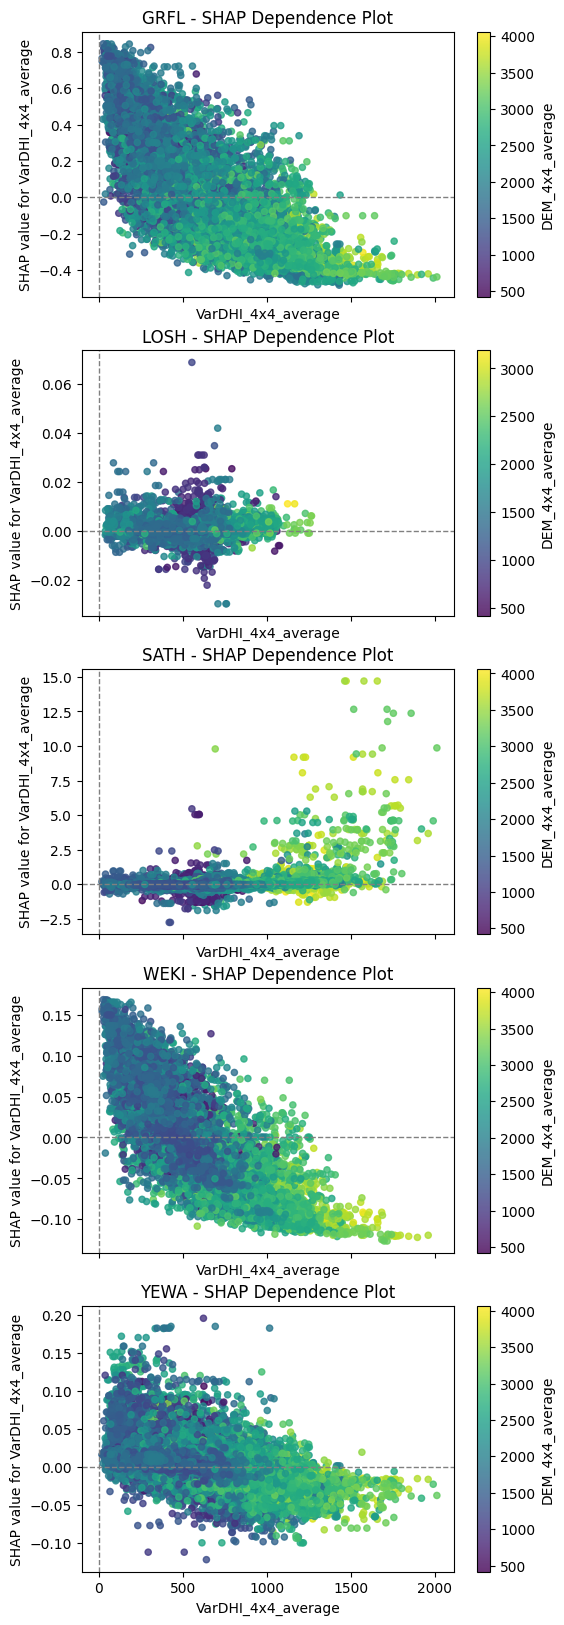

In [60]:
import pandas as pd
import shap
import pickle
import matplotlib.pyplot as plt

# Load SHAP values
#species_list = ["HAFL","OSFL","RCKI","WETA","YRWA"]  # Forest
#species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] # Woodland
#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
species_list = ["GRFL","LOSH","SATH","WEKI","YEWA"] # Shrubland

predictor_cols = ['tmax_average']

# Set up subplots
n_species = len(species_list)
fig, axes = plt.subplots(n_species, 1, figsize=(6, 4 * n_species), sharex=True)

# Ensure axes is iterable
if n_species == 1:
    axes = [axes]

for idx, species in enumerate(species_list):
    # Load the data
    data_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ {species} .csv'
    data = pd.read_csv(data_path)

    # Load SHAP values
    shap_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/SHAP/{species}_8Predictors.pkl'
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

    shap_values_array = shap_values.values if hasattr(shap_values, "values") else shap_values

    # Predictor columns and input features
    predictor_cols = [
        'CumDHI_4x4_average',
        'DEM_4x4_average',
        'Forest_percentage_4x4_average_reprojected',
        'Grassland_percentage_4x4_average_reprojected',
        'precip_average',
        'Shrubland_percentage_4x4_average_reprojected',
        'tmax_average',
        'VarDHI_4x4_average'
    ]
    X = data[predictor_cols]

    # Feature and interaction index
    feature = 'VarDHI_4x4_average'
    interaction_feature = 'DEM_4x4_average'

    # Index of the feature in SHAP array
    feature_index = predictor_cols.index(feature)

    # Extract values
    shap_vals = shap_values_array[:, feature_index]
    feature_vals = X[feature].values
    interaction_vals = X[interaction_feature].values

    # Plot manually with matplotlib
    ax = axes[idx]
    scatter = ax.scatter(
        feature_vals, shap_vals,
        c=interaction_vals,
        cmap='viridis',
        s=20,
        alpha=0.8
    )
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label(interaction_feature)

    ax.set_xlabel(feature)
    ax.set_ylabel(f'SHAP value for {feature}')
    ax.set_title(f'{species} - SHAP Dependence Plot')
    ax.axhline(0, color='gray', linewidth=1, linestyle='--')
    ax.axvline(0, color='gray', linewidth=1, linestyle='--')

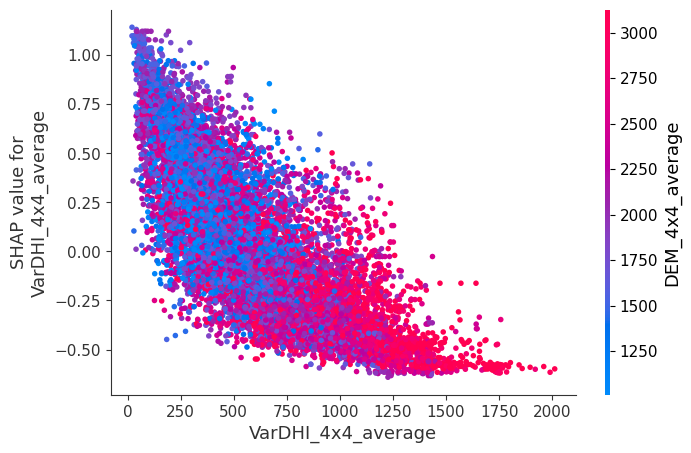

In [15]:
#predictor_cols = ['CumDHI_4x4_average', 'DEM_4x4_average', 'Forest_percentage_4x4_average_reprojected', 'Grassland_percentage_4x4_average_reprojected', 'precip_average', 'Shrubland_percentage_4x4_average_reprojected', 'tmax_average', 'VarDHI_4x4_average']  # Update with your actual columns

shap.dependence_plot('VarDHI_4x4_average', shap_values, X, interaction_index='DEM_4x4_average')

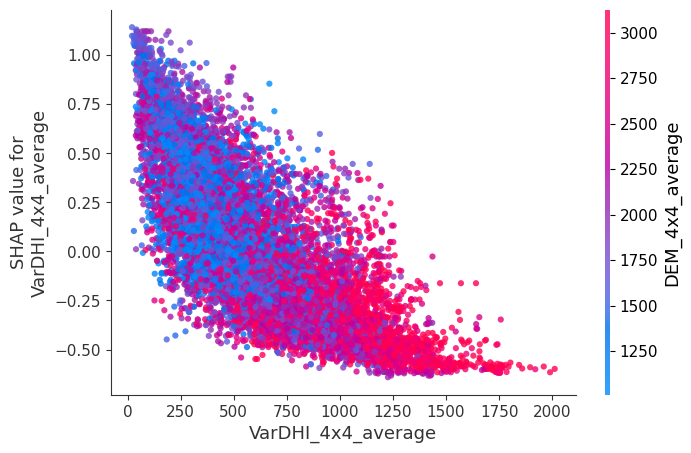

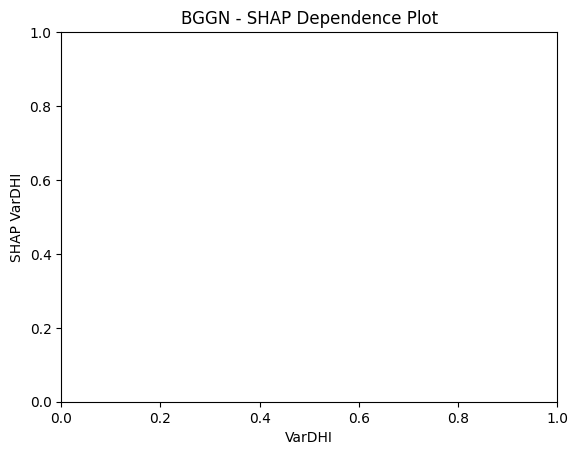

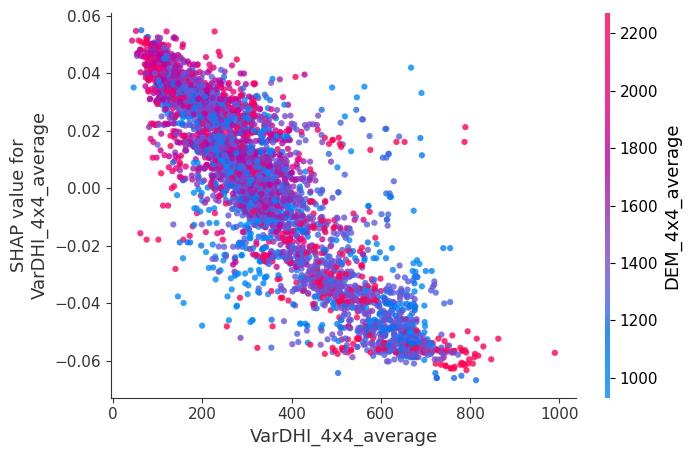

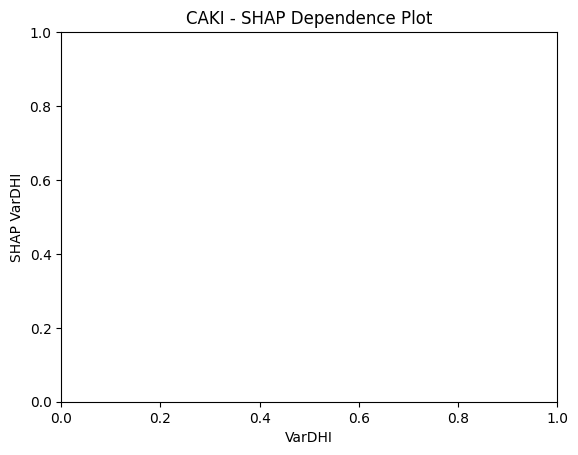

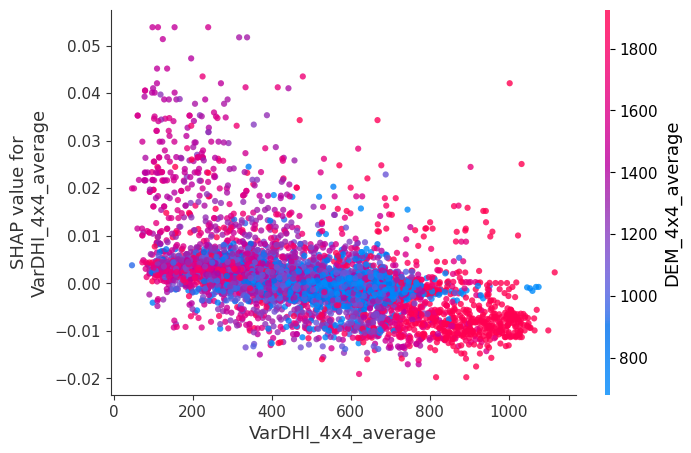

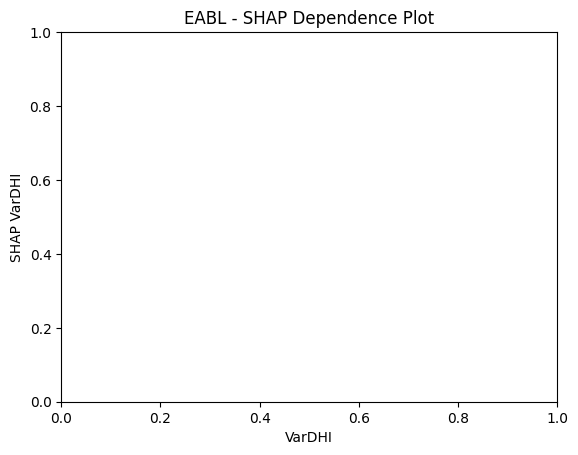

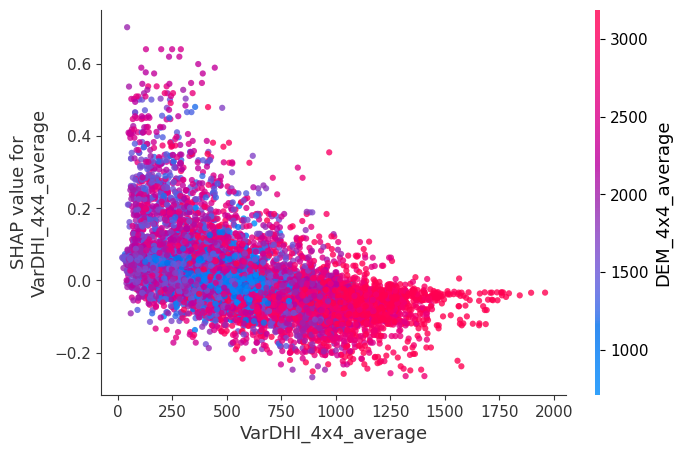

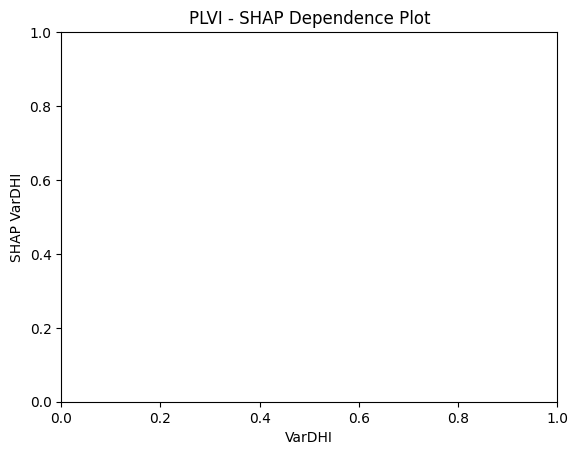

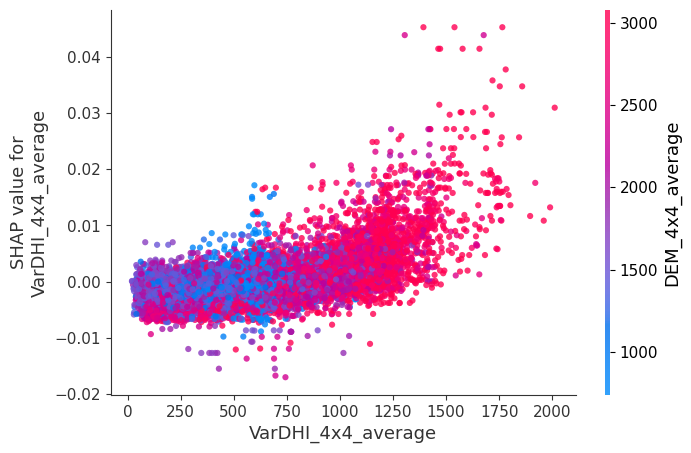

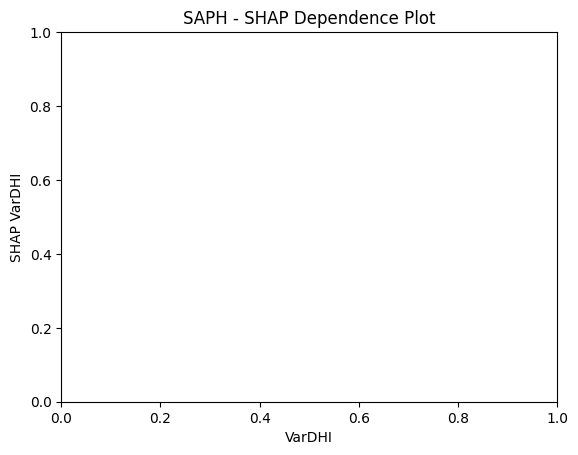

In [23]:
import pandas as pd
import shap
import pickle
import matplotlib.pyplot as plt

# Load SHAP values
#species_list = ["HAFL","OSFL","RCKI","WETA","YRWA"]  #Forest
species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] # Woodland
#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
#species_list = ["GRFL","LOSH","SATH","WEKI","YEWA"] # Shrubland

# Loop over each species
for species in species_list:
    # Load the data
    data_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ {species} .csv'
    data = pd.read_csv(data_path)

    # Load SHAP values
    shap_path = f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/{species}_8Predictors.pkl'
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

    # If SHAP values is an Explanation object, convert to array
    shap_values_array = shap_values.values if hasattr(shap_values, "values") else shap_values

    # Feature columns used in the model
    predictor_cols = [
        'CumDHI_4x4_average',
        'DEM_4x4_average',
        'Forest_percentage_4x4_average_reprojected',
        'Grassland_percentage_4x4_average_reprojected',
        'precip_average',
        'Shrubland_percentage_4x4_average_reprojected',
        'tmax_average',
        'VarDHI_4x4_average'
    ]

    # Prepare the feature matrix
    X = data[predictor_cols]

    # Plot SHAP dependence plot
    shap.dependence_plot(
        'VarDHI_4x4_average',
        shap_values_array,
        X,
        interaction_index='DEM_4x4_average',
        show=True,
        dot_size=20,
        alpha=0.8
    )

    plt.title(f'{species} - SHAP Dependence Plot')
    plt.xlabel('VarDHI')
    plt.ylabel('SHAP VarDHI')


## Multiscale

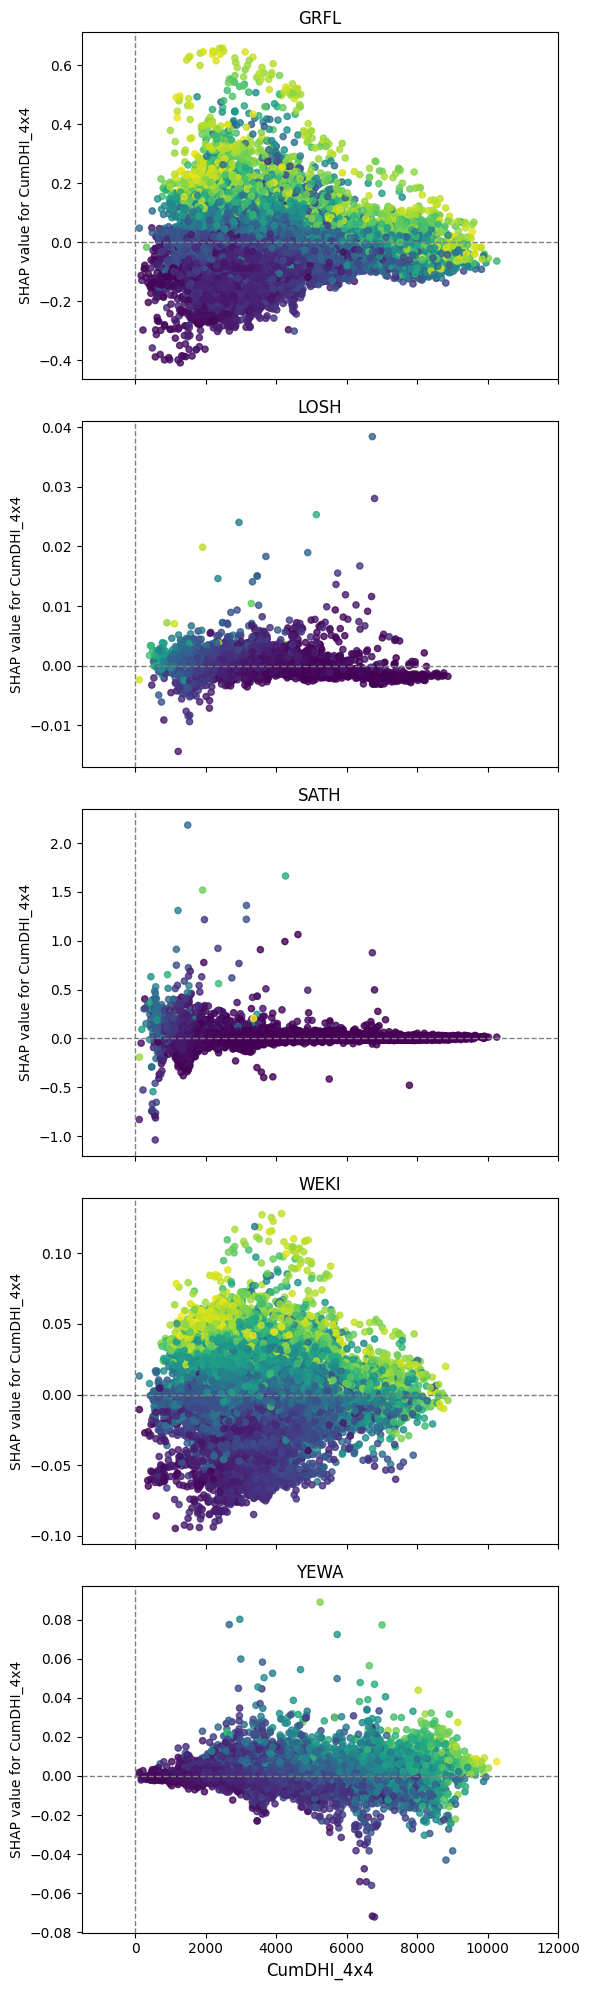

In [ ]:
import pandas as pd
import shap
import pickle
import matplotlib.pyplot as plt

# Load SHAP values
#species_list = ["HAFL","OSFL","RCKI","WETA","YRWA"]  #Forest
#species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] # Woodland
#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
species_list = ["GRFL","LOSH","SATH","WEKI","YEWA"] # Shrubland


predictor_cols = ['CumDHI_4x4']

# Set up subplots
n_species = len(species_list)
fig, axes = plt.subplots(n_species, 1, figsize=(6, 4 * n_species), sharex=True)

# Ensure axes is iterable
if n_species == 1:
    axes = [axes]

for idx, species in enumerate(species_list):
    # Load the data
    data_path = f'/content/drive/My Drive/SHAP/Shrubland/Raster_extracted_Pred_ {species} .csv'
    data = pd.read_csv(data_path)

    # Load SHAP values
    shap_path = f'/content/drive/My Drive/SHAP/Shrubland/Predictor_wise/{species}_CumDHI.pkl'
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

    # Prepare data
    X = data[predictor_cols]
    shap_values = shap_values.values if hasattr(shap_values, "values") else shap_values

    # Plot for the single predictor
    col = predictor_cols[0]
    ax = axes[idx]
    scatter = ax.scatter(
        X[col], shap_values[:, 0],
        c=data['Predicted'],
        cmap='viridis', s=20, alpha=0.8
    )
    ax.set_title(f'{species}', fontsize=12)
    ax.set_ylabel(f'SHAP value for {col}')

    # Remove default gridlines and add only x=0 and y=0 lines
    ax.grid(False)
    ax.axhline(0, color='gray', linewidth=1, linestyle='--')
    ax.axvline(0, color='gray', linewidth=1, linestyle='--')
    ax.set_xlim(right=12000)  # Or use ax.set_xlim(0, 12000) if needed

# Common X label
axes[-1].set_xlabel(f'{col}', fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
shap_values.shape, data.shape

((22358, 9), (44716, 44))

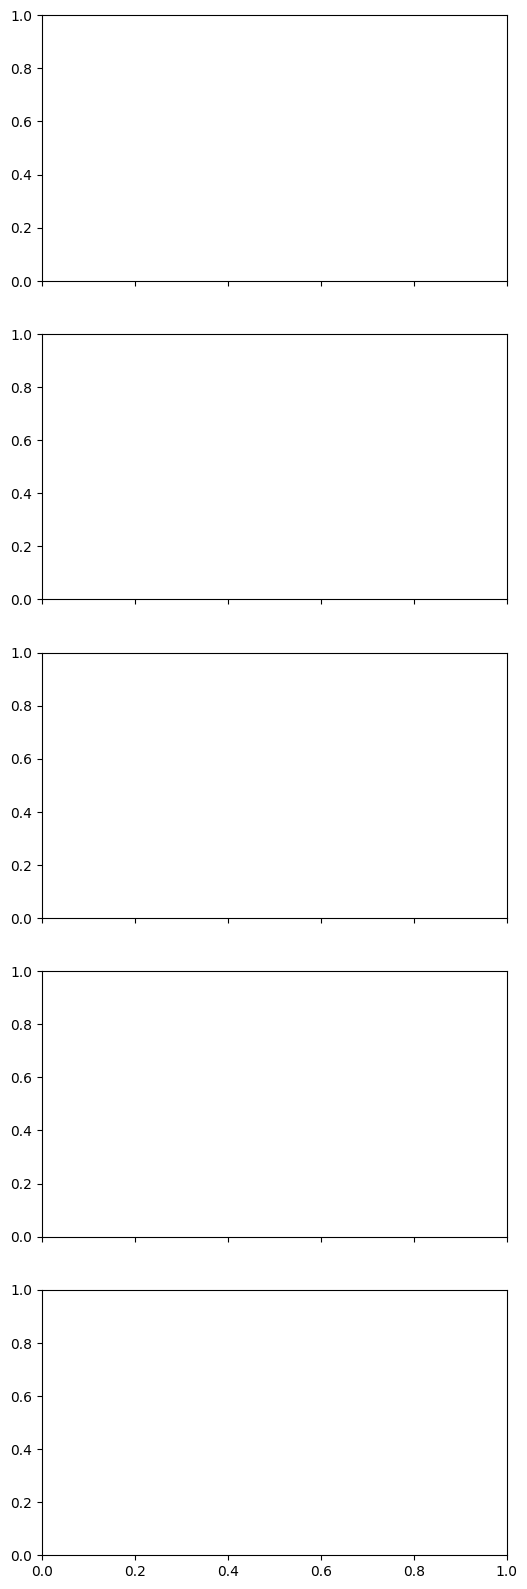

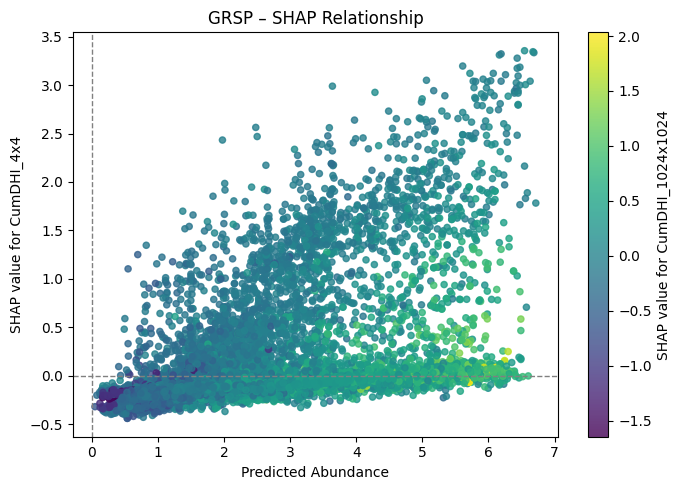

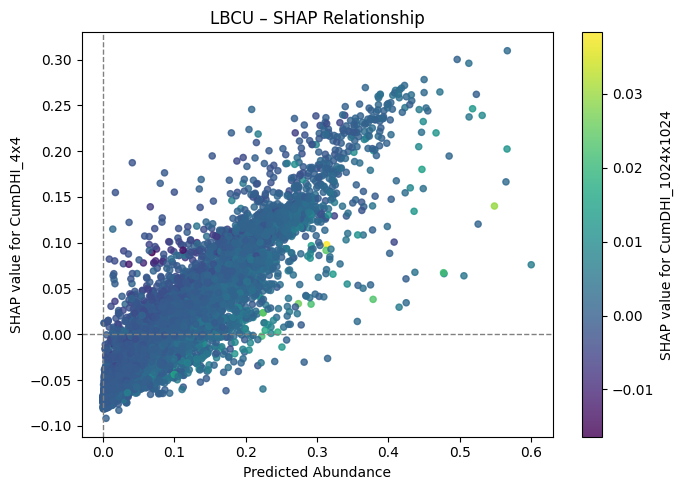

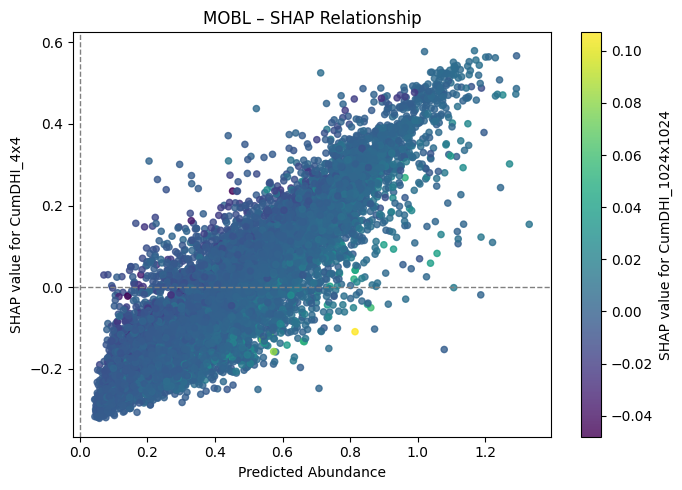

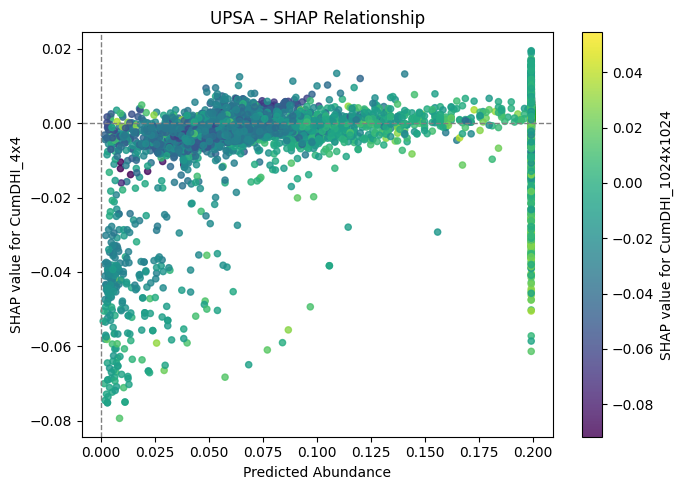

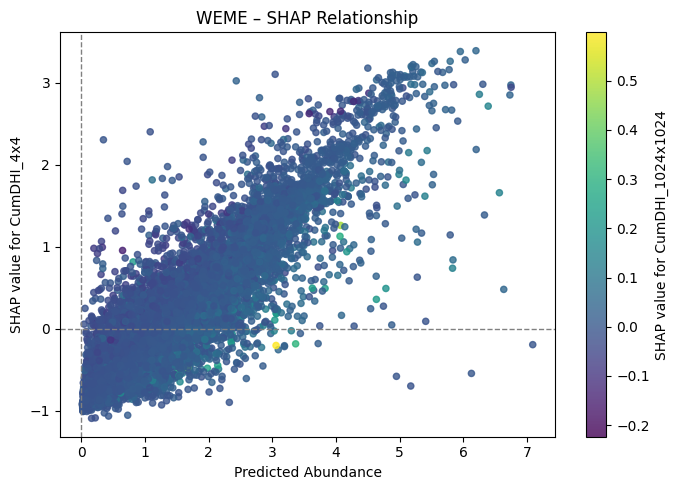

In [41]:
import pandas as pd
import shap
import pickle
import matplotlib.pyplot as plt

# Load SHAP values
#species_list = ["HAFL","OSFL","RCKI","WETA","YRWA"]  #Forest
#species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] # Woodland
species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
#species_list = ["GRFL","LOSH","SATH","WEKI","YEWA"] # Shrubland

#predictor_cols = ['CumDHI_4x4']

# Set up subplots
n_species = len(species_list)
fig, axes = plt.subplots(n_species, 1, figsize=(6, 4 * n_species), sharex=True)

# Ensure axes is iterable
if n_species == 1:
    axes = [axes]

for idx, species in enumerate(species_list):
    # Load the data
    data_path = f'/content/drive/My Drive/SHAP/Grassland/Raster_extracted_Pred_ {species} .csv'
    data = pd.read_csv(data_path)

    # Load SHAP values
    shap_path = f'/content/drive/My Drive/SHAP/Grassland/Predictor_wise/{species}_CumDHI.pkl'
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

    shap_values_array = shap_values.values if hasattr(shap_values, "values") else shap_values

    # Feature and interaction
    predictor_cols = [
        'CumDHI_1024x1024', 'CumDHI_128x128', 'CumDHI_16x16',
        'CumDHI_256x256', 'CumDHI_32x32', 'CumDHI_4x4', 'CumDHI_512x512',
        'CumDHI_64x64', 'CumDHI_8x8'
    ]
    X = data[predictor_cols]

    feature = 'CumDHI_4x4'
    interaction_feature = 'CumDHI_1024x1024'

    feature_index = predictor_cols.index(feature)
    interaction_index = predictor_cols.index(interaction_feature)

    # Assign values for plot
    x_vals = data['Predicted']                           # x-axis
    y_vals = shap_values_array[:, feature_index]         # y-axis
    color_vals = shap_values_array[:, interaction_index] # color

    # Plot
    plt.figure(figsize=(7, 5))
    scatter = plt.scatter(
        x_vals, y_vals,
        c=color_vals,
        cmap='viridis',
        s=20,
        alpha=0.8
    )
    cbar = plt.colorbar(scatter)
    cbar.set_label(f'SHAP value for {interaction_feature}')

    plt.xlabel('Predicted Abundance')
    plt.ylabel(f'SHAP value for {feature}')
    plt.title(f'{species} – SHAP Relationship')
    plt.axhline(0, color='gray', linewidth=1, linestyle='--')
    plt.axvline(0, color='gray', linewidth=1, linestyle='--')
    plt.tight_layout()
    plt.show()

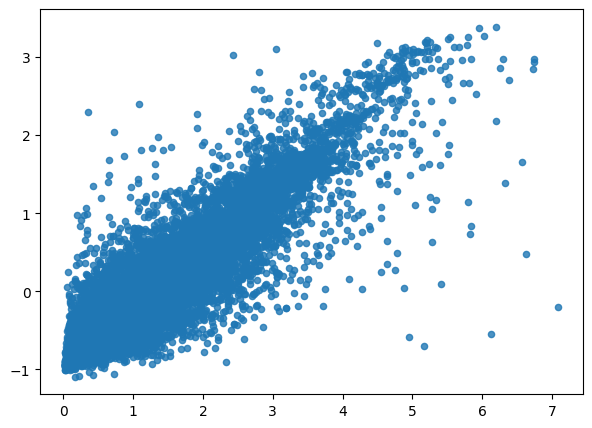

In [45]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(
        x_vals, y_vals,
        s=20,
        alpha=0.8
    )

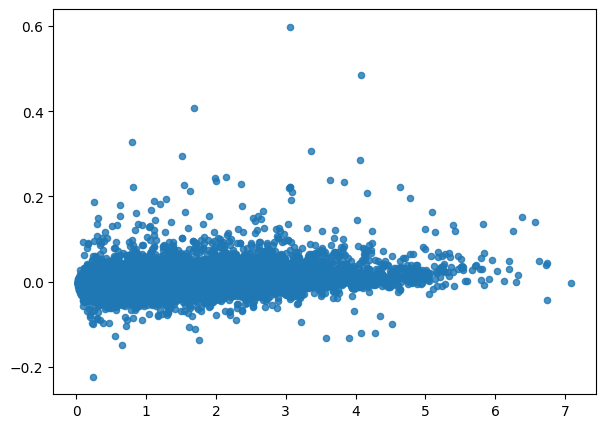

In [46]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(
        x_vals, color_vals,
        s=20,
        alpha=0.8
    )

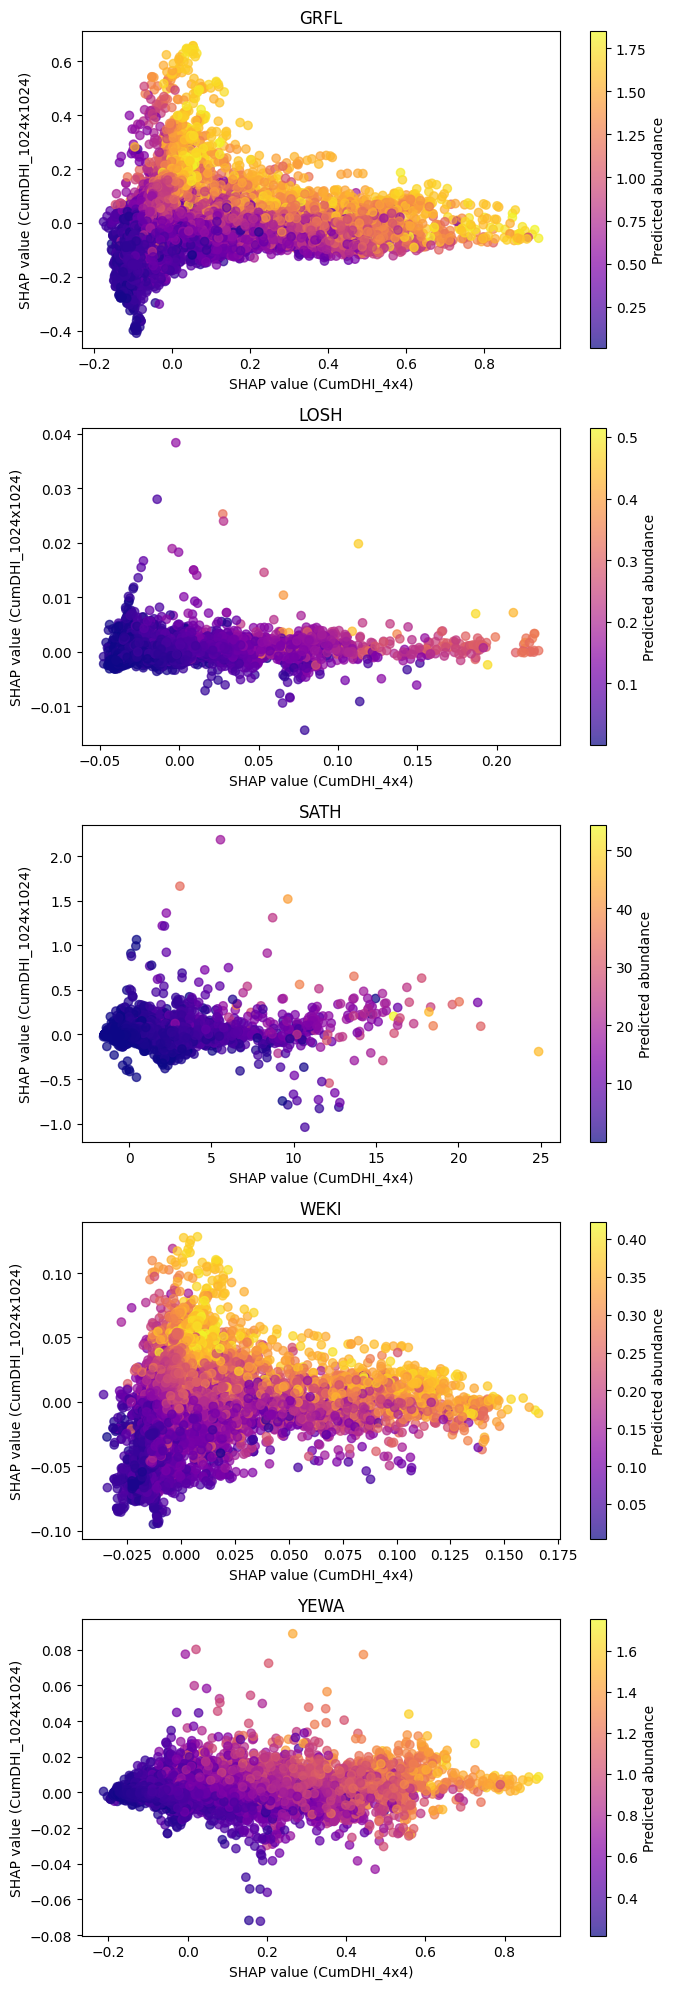

In [55]:
import pandas as pd
import shap
import pickle
import matplotlib.pyplot as plt

#species_list = ["HAFL","OSFL","RCKI","WETA","YRWA"]  #Forest
#species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] # Woodland
#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
species_list = ["GRFL","LOSH","SATH","WEKI","YEWA"] # Shrubland

predictor_cols = [
    'CumDHI_1024x1024', 'CumDHI_128x128', 'CumDHI_16x16',
    'CumDHI_256x256', 'CumDHI_32x32', 'CumDHI_4x4', 'CumDHI_512x512',
    'CumDHI_64x64', 'CumDHI_8x8'
]

n_species = len(species_list)
fig, axes = plt.subplots(n_species, 1, figsize=(7, 4 * n_species))  # removed sharex and sharey

if n_species == 1:
    axes = [axes]

for idx, species in enumerate(species_list):
    data_path = f'/content/drive/My Drive/SHAP/Shrubland/Raster_extracted_Pred_ {species} .csv'
    shap_path = f'/content/drive/My Drive/SHAP/Shrubland/Predictor_wise/{species}_CumDHI.pkl'

    data = pd.read_csv(data_path)
    with open(shap_path, 'rb') as f:
        shap_values = pickle.load(f)

    shap_values_array = shap_values.values if hasattr(shap_values, "values") else shap_values
    shap_df = pd.DataFrame(shap_values_array, columns=predictor_cols)

    ax = axes[idx]
    sc = ax.scatter(
        shap_df['CumDHI_4x4'],
        shap_df['CumDHI_1024x1024'],
        c=data['Predicted'],  # or another column representing prediction
        cmap='plasma',
        alpha=0.7
    )
    ax.set_title(f"{species}")
    ax.set_xlabel("SHAP value (CumDHI_4x4)")
    ax.set_ylabel("SHAP value (CumDHI_1024x1024)")

    fig.colorbar(sc, ax=ax, label="Predicted abundance")

plt.tight_layout()
#plt.suptitle("SHAP Comparison: CumDHI_4x4 vs 1024x1024", y=1.02, fontsize=16)
plt.show()


In [33]:
data.columns  # 'CumDHI_1024x1024', 'CumDHI_128x128','CumDHI_16x16'

Index(['uniqueID', 'PointLatit', 'PointLongi', 'Predicted', 'SE', 'lower',
       'upper', 'CumDHI_1024x1024', 'CumDHI_128x128', 'CumDHI_16x16',
       'CumDHI_256x256', 'CumDHI_32x32', 'CumDHI_4x4', 'CumDHI_512x512',
       'CumDHI_64x64', 'CumDHI_8x8', 'DEM_1024x1024', 'DEM_128x128',
       'DEM_16x16', 'DEM_256x256', 'DEM_32x32', 'DEM_4x4', 'DEM_512x512',
       'DEM_64x64', 'DEM_8x8', 'MinDHI_1024x1024', 'MinDHI_128x128',
       'MinDHI_16x16', 'MinDHI_256x256', 'MinDHI_32x32', 'MinDHI_4x4',
       'MinDHI_512x512', 'MinDHI_64x64', 'MinDHI_8x8', 'VarDHI_1024x1024',
       'VarDHI_128x128', 'VarDHI_16x16', 'VarDHI_256x256', 'VarDHI_32x32',
       'VarDHI_4x4', 'VarDHI_512x512', 'VarDHI_64x64', 'VarDHI_8x8'],
      dtype='object')